# <center>Joy Detection from English Comments – Binary Classification with Imbalanced Data</center>

## Introduction - A Binary Classification Problem with Imbalanced Data
##### **Definition:** Emotion detection is the task of identifying the emotion expressed by a person in a piece of text using natural language processing and machine learning techniques. In this notebook we ask only one question: **does the comment express Joy or not?** Each comment belongs to exactly one of **two** classes (**Joy** / **Not Joy**), so it is a **binary classification** problem.
##### **Imbalanced Data:** In this dataset only about **one third** of the comments are *Joy* and two thirds are *Not Joy*. When one class has many more instances than the other, the data is called **imbalanced (biased)**. This notebook shows why imbalanced data is a problem and how to handle it.
##### **Applications:** Detecting happy / satisfied customers in reviews, measuring positive reactions to a product launch on social media, finding positive moments in chat or support conversations, and mental-health monitoring.

## Input & Output

##### **Input:** An English comment
##### **Output:** Predicted label (Joy / Not Joy)

## Examples (Emotion Dataset)

| **Sr. No** | **Comment (Input)**                                         | **Original Emotion** | **Label (Output)** |
| ---------- | ----------------------------------------------------------- | -------------------- | ------------------ |
| 1          | I am feeling really excited about my results today.         | Joy                  | Joy                |
| 2          | I feel so lonely since my best friend moved away.           | Sadness              | Not Joy            |
| 3          | I feel furious that they cancelled my order without asking. | Anger                | Not Joy            |
| 4          | I feel nervous and scared about tomorrow's exam.            | Fear                 | Not Joy            |
| 5          | I feel so lucky and loved to have such a caring family.     | Love                 | Not Joy            |
| 6          | I was amazed when I saw the result, it was so unexpected.   | Surprise             | Not Joy            |

## Developer and System Information

| **Field**                     | **Details**                                                                 |
|-------------------------------|-------------------------------------------------------------------------|
| **Developer Name**            | Haq Nawaz; Dr. Rao Muhammad Adeel Nawab                                 |
| **LinkedIn (Haq Nawaz)**      | https://www.linkedin.com/in/haqnawaz99/                                 |
| **LinkedIn (Dr. Rao Muhammad Adeel Nawab)** | https://www.linkedin.com/in/rao-muhammad-adeel-nawab/?trk=feed_main-feed-card_feed-actor-name |
| **Program Name**              | joy_detection_imbalanced_binary_classification                          |
| **IDE**                       | Jupyter Notebook / Google Colab                                         |
| **Programming Language**      | Python 3.10                                                             |
| **Operating System**          | Windows 11                                                              |
| **Libraries**                 | pandas 2.3.3, numpy, matplotlib 3.10, seaborn 0.13.2, scikit-learn 1.7.2, joblib 1.6.0 |
| **Date of Completion**        | 10-Nov-2026                                                              |
| **Website**                   | www.ilmoirfan.com; www.ilmoirfan.ai                                      |
| **Email**                     | info@ilmoirfan.com; info@ilmoirfan.ai                                    |

## Table of Content

- *Step 1:* Import Libraries

- *Step 2:* Load Sample Data (emotion_binary_sample_data.csv)
  - Step 2.1: View Shape and First Rows of the Dataset
  - Step 2.2: Count Number of Instances for Each Original Emotion
  - Step 2.3: Convert 6 Emotions into 2 Classes (Joy / Not Joy)
  - Step 2.4: Count Number of Instances for Each Class
  - Step 2.5: What is Imbalanced (Biased) Data?

- *Step 3:* Data Cleaning and Preprocessing
  - Step 3.1: Set Stopwords
  - Step 3.2: Write Functions to Clean Text
  - Step 3.3: Drop Rows with NaN Values in Text Column
  - Step 3.4: Apply Functions to Clean Text
  - Step 3.5: Data After Cleaning and Preprocessing
  - Step 3.6: Save Cleaned Data as Separate CSV File (called clean_emotion_binary_sample_data.csv)

- *Step 4:* Split Sample Data into Training and Testing Sets (80% / 20%, Stratified)
  - Step 4.1: Why Stratify? (split without and with stratify)
  - Step 4.2: Final Stratified Split

- *Step 5:* Feature Extraction from Text (using TF-IDF Vectorizer)
  - Step 5.1: Train tfidf_vectorizer using Training Data
  - Step 5.2: Transform Training Text into Feature Vectors using tfidf_vectorizer (trained in Step 5.1)
  - Step 5.3: Transform Testing Text into Feature Vectors using tfidf_vectorizer (trained in Step 5.1)
  - Step 5.4: Save tfidf_vectorizer

- *Step 6:* Execute the Training Phase
  - Step 6.1: Baseline Model (always predicts the majority class)
  - Step 6.2: Variation 1 – Six Algorithms without Class Weights
  - Step 6.3: Variation 2 – Algorithms with class_weight = 'balanced'
  - Step 6.4: Train All Models
  - Step 6.5: Save All Trained Models

- *Step 7:* Execute the Testing Phase
  - Step 7.1: Load All Trained Models (saved in Step 6.5)
  - Step 7.2: Evaluate All Trained Models (using Testing Feature Vectors created in Step 5.3)
  - Step 7.3: The Accuracy Trap – Results of the Baseline Model
  - Step 7.4: Confusion Matrices – Variation 1 (without Class Weights)
  - Step 7.5: Confusion Matrices – Variation 2 (with class_weight = 'balanced')

- *Step 8:* Compare the Algorithms
  - Step 8.1: Comparison Table of All Models (sorted by F1-Score of Joy)
  - Step 8.2: Variation 1 vs Variation 2 (Effect of class_weight = 'balanced')
  - Step 8.3: Comparison Bar Chart (Recall and F1-Score of Joy)
  - Step 8.4: Select and Save the Best Model
  - Step 8.5: Detailed Classification Report of the Best Model

- *Step 9:* Execute the Application Phase
  - Step 9.1: Load tfidf_vectorizer (saved in Step 5.4)
  - Step 9.2: Load the Best Model (saved in Step 8.4)
  - Step 9.3: Take Input from User
  - Step 9.4: Clean and Preprocess User Input (exactly as you did for Sample Data in Step 3)
  - Step 9.5: Apply tfidf_vectorizer to Cleaned and Preprocessed User Input
  - Step 9.6: Model Prediction

- *Step 10:* Execute the Feedback Phase

- *Lessons Learned about Imbalanced Data*

- *Conclusion*

## Data - Download Link
##### https://huggingface.co/datasets/dair-ai/emotion
##### **Source:** Saravia et al. (2018), *CARER: Contextualized Affect Representations for Emotion Recognition*, EMNLP. English Twitter messages labelled with six emotions (for educational and research use).
##### **Sample Data used in this notebook (emotion_binary_sample_data.csv):** 2,400 comments taken **randomly** (random_state = 42) from the training split of the dataset after removing duplicate comments. The sample is **not balanced on purpose** – it keeps the natural proportion of each emotion, which makes the Joy / Not Joy problem imbalanced.

## Code – Joy Detection from English Comments

### Data Collection and Data Understanding

### Step 1: Import Libraries

In [1]:
# Regular expressions library for text cleaning (e.g., removing special characters, numbers)
import re

# Time library to measure how long each algorithm takes to train
import time

# Pandas for loading and manipulating datasets (DataFrame structure)
import pandas as pd

# Matplotlib and Seaborn for plots (count plots, confusion matrices, bar charts)
import matplotlib.pyplot as plt
import seaborn as sns

# Joblib to save and load trained models
import joblib

# Built-in English stopwords list of scikit-learn (no internet download needed)
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# TF-IDF Vectorizer converts text into numerical feature vectors
from sklearn.feature_extraction.text import TfidfVectorizer

# Splits the dataset into training and testing sets
from sklearn.model_selection import train_test_split

# Baseline model (always predicts the most frequent class)
from sklearn.dummy import DummyClassifier

# Machine Learning Algorithms (6 algorithms to compare)
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

### Step 2: Load Sample Data (emotion_binary_sample_data.csv)

In [2]:
# In Google Colab: upload emotion_binary_sample_data.csv from your computer.
# On your own computer (Jupyter): the file is read from the same folder as this notebook.
try:
    from google.colab import files
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
except ImportError:
    file_name = "emotion_binary_sample_data.csv"

# Load the dataset into a pandas DataFrame (columns: Comment, Emotion)
data = pd.read_csv(file_name)

print("\n\nEmotion Sample Data:")
print("====================\n")
print("File name =", file_name)



Emotion Sample Data:

File name = emotion_binary_sample_data.csv


#### Step 2.1: View Shape and First Rows of the Dataset

In [3]:
# Shape = (number of rows, number of columns)
print("Shape of the dataset =", data.shape)
print("Columns in the dataset =", list(data.columns))
print()

# Show the first 10 comments with their original emotion
data.head(10)

Shape of the dataset = (2400, 2)
Columns in the dataset = ['Comment', 'Emotion']



,Comment,Emotion
0,i think he is what really made us decide to st...,joy
1,i feel like i tend be more passionate about th...,joy
2,i feel a little more relaxed,joy
3,i feel about the scratches the way i feel abou...,love
4,i was sick of feeling so lethargic all the time,sadness
5,ive learned in this short journey thus far is ...,sadness
6,i feel so comfortable wear it,joy
7,i can hear the hum you make at the feeling of ...,fear
8,i start an aimless internet search when im fee...,surprise
9,when i heard a rumour that the st year exam re...,fear


#### Step 2.2: Count Number of Instances for Each Original Emotion

Number of instances for each original emotion:
Emotion
joy         815
sadness     673
anger       319
fear        282
love        226
surprise     85
Name: count, dtype: int64


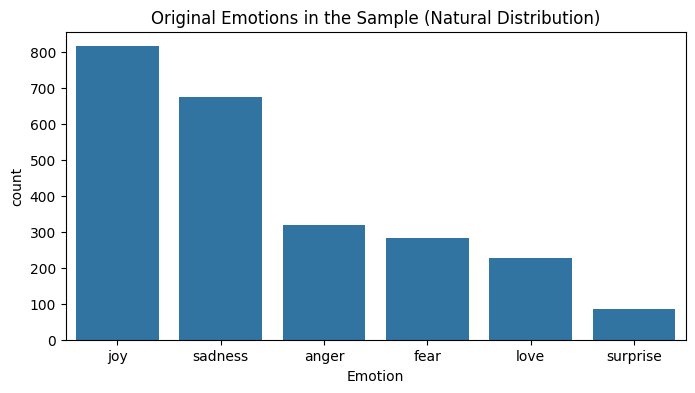

In [4]:
# The original dataset has 6 emotions. Because the sample was taken randomly,
# the emotions are NOT equal in number (natural distribution).
print("Number of instances for each original emotion:")
print(data['Emotion'].value_counts())

plt.figure(figsize=(8, 4))
sns.countplot(x='Emotion', data=data, order=data['Emotion'].value_counts().index)
plt.title("Original Emotions in the Sample (Natural Distribution)")
plt.show()

#### Step 2.3: Convert 6 Emotions into 2 Classes (Joy / Not Joy)

##### **Joy** stays **Joy**. All other emotions (sadness, anger, fear, love, surprise) become **Not Joy**. This is called a **One-vs-Rest** conversion.

In [5]:
# Create the new binary label column
data['Label'] = data['Emotion'].apply(lambda emotion: 'Joy' if emotion == 'joy' else 'Not Joy')

# Check the conversion: which original emotions went into each class
print("Original emotions inside each class:")
print(pd.crosstab(data['Emotion'], data['Label']))

Original emotions inside each class:
Label     Joy  Not Joy
Emotion               
anger       0      319
fear        0      282
joy       815        0
love        0      226
sadness     0      673
surprise    0       85


#### Step 2.4: Count Number of Instances for Each Class

In [6]:
label_counts = data['Label'].value_counts()
print("Number of instances for each class:")
print(label_counts)

# Percentage of each class
print("\nPercentage of each class:")
print((data['Label'].value_counts(normalize=True) * 100).round(2))

# Imbalance ratio = majority class / minority class
imbalance_ratio = label_counts.max() / label_counts.min()
print(f"\nImbalance ratio (Not Joy : Joy) = {imbalance_ratio:.2f} : 1")

Number of instances for each class:
Label
Not Joy    1585
Joy         815
Name: count, dtype: int64

Percentage of each class:
Label
Not Joy    66.04
Joy        33.96
Name: proportion, dtype: float64

Imbalance ratio (Not Joy : Joy) = 1.94 : 1


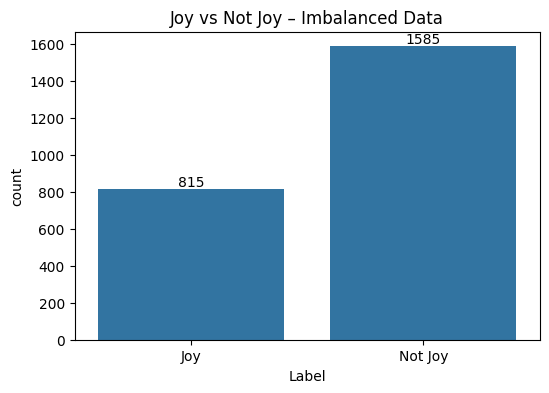

In [7]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Label', data=data, order=['Joy', 'Not Joy'])
for container in ax.containers:
    ax.bar_label(container)
plt.title("Joy vs Not Joy – Imbalanced Data")
plt.show()

#### Step 2.5: What is Imbalanced (Biased) Data?
##### **Definition:** A dataset is **imbalanced** when one class (the **majority class**, here *Not Joy*) has many more instances than the other class (the **minority class**, here *Joy*). Our data has about **2 Not Joy comments for every 1 Joy comment**.
##### **Real-world examples:** fraud detection (very few fraud transactions), disease diagnosis (few patients have the disease), spam detection, machine-failure prediction. Very often, the **minority class is the one we care about most**.
##### **Why is it a problem?**
- A model learns mostly from the majority class, so it becomes **biased** towards predicting the majority class.
- **Accuracy becomes misleading:** a "model" that always says *Not Joy* is already about 66% accurate without learning anything (we will prove this in Step 7.3).
##### **What we will do in this notebook:**
1. Use a **stratified** split so both training and testing sets keep the same Joy / Not Joy proportion (Step 4).
2. Train a **baseline** model that always predicts the majority class (Step 6.1).
3. Look at **Precision, Recall and F1-Score of the Joy class** – not only accuracy (Step 7).
4. Train every algorithm in **two variations**: **without** class weights and **with `class_weight='balanced'`**, and compare them (Steps 6 – 8).

### Step 3: Data Cleaning and Preprocessing

#### Step 3.1: Set Stopwords

In [8]:
# Stopwords are very common words (e.g., "the", "is", "and") that carry little meaning.
# We use the built-in English stopwords list of scikit-learn.
stop_words = set(ENGLISH_STOP_WORDS)

print("Number of stopwords =", len(stop_words))
print("Some stopwords:", sorted(stop_words)[:20])

Number of stopwords = 318
Some stopwords: ['a', 'about', 'above', 'across', 'after', 'afterwards', 'again', 'against', 'all', 'almost', 'alone', 'along', 'already', 'also', 'although', 'always', 'am', 'among', 'amongst', 'amoungst']


#### Step 3.2: Write Functions to Clean Text

#### Function 1: Remove Symbols and Numbers

In [9]:
def remove_symbols_and_numbers(text):
    # Keep only English letters and spaces (remove digits, punctuation, emojis, etc.)
    return re.sub(r'[^a-zA-Z\s]', '', text)

#### Function 2: Convert Text to Lowercase

In [10]:
def convert_to_lowercase(text):
    # Convert all characters to lowercase so that "Happy" and "happy" are the same word
    return text.lower()

#### Function 3: Remove Stopwords

In [11]:
def remove_stopwords(text):
    # Split the text into words, keep only the words that are not stopwords, join them back
    return ' '.join(word for word in text.split() if word not in stop_words)

#### Function 4: Complete Cleaning (all three functions together)

In [12]:
def clean_text(text):
    # Apply the three cleaning functions one after the other
    text = remove_symbols_and_numbers(text)
    text = convert_to_lowercase(text)
    text = remove_stopwords(text)
    return text

#### Step 3.3: Drop Rows with NaN Values in Text Column

In [13]:
# Remove rows where the comment is missing
print("Rows before dropping NaN =", len(data))
data = data.dropna(subset=['Comment']).reset_index(drop=True)
print("Rows after dropping NaN  =", len(data))

Rows before dropping NaN = 2400
Rows after dropping NaN  = 2400


#### Step 3.4: Apply Functions to Clean Text

In [14]:
# Keep a copy of the original comment so that we can compare before and after cleaning
data['Original_Comment'] = data['Comment']

# Apply the complete cleaning function to every comment
data['Comment'] = data['Comment'].apply(clean_text)

# Compare a few comments before and after cleaning
print("\nBefore and After Cleaning:")
print("==========================\n")
for i in range(5):
    print("Before :", data.loc[i, 'Original_Comment'])
    print("After  :", data.loc[i, 'Comment'])
    print()


Before and After Cleaning:

Before : i think he is what really made us decide to stay with multiband because he made us feel valued and listen to the fact i am a student and need to do homework
After  : think really decide stay multiband feel valued listen fact student need homework

Before : i feel like i tend be more passionate about things that are less popular to talk about
After  : feel like tend passionate things popular talk

Before : i feel a little more relaxed
After  : feel little relaxed

Before : i feel about the scratches the way i feel about my wrinkles i am fond of them and regard them as evidence of a life well lived
After  : feel scratches way feel wrinkles fond regard evidence life lived

Before : i was sick of feeling so lethargic all the time
After  : sick feeling lethargic time



#### Step 3.5: Data After Cleaning and Preprocessing

In [15]:
# Remove the helper column and any comment that became empty after cleaning
data = data.drop(columns=['Original_Comment'])
data = data[data['Comment'].str.strip() != ''].reset_index(drop=True)

print("\n\nEmotion Data After Preprocessing:")
print("=================================\n")
print("Shape of the cleaned dataset =", data.shape)
data.head(10)



Emotion Data After Preprocessing:

Shape of the cleaned dataset = (2400, 3)


,Comment,Emotion,Label
0,think really decide stay multiband feel valued...,joy,Joy
1,feel like tend passionate things popular talk,joy,Joy
2,feel little relaxed,joy,Joy
3,feel scratches way feel wrinkles fond regard e...,love,Not Joy
4,sick feeling lethargic time,sadness,Not Joy
5,ive learned short journey far know body sugar ...,sadness,Not Joy
6,feel comfortable wear,joy,Joy
7,hear hum make feeling warmth legs shift little...,fear,Not Joy
8,start aimless internet search im feeling curious,surprise,Not Joy
9,heard rumour st year exam results fear failures,fear,Not Joy


#### Step 3.6: Save Cleaned Data as Separate CSV File (called clean_emotion_binary_sample_data.csv)

In [16]:
data.to_csv("clean_emotion_binary_sample_data.csv", index=False)
print("Cleaned data saved as 'clean_emotion_binary_sample_data.csv'")

Cleaned data saved as 'clean_emotion_binary_sample_data.csv'


### Step 4: Split Sample Data into Training and Testing Sets (80% / 20%, Stratified)

In [17]:
# Features (X) = cleaned comment, Label (y) = Joy / Not Joy
X = data['Comment']
y = data['Label']

#### Step 4.1: Why Stratify? (split without and with stratify)

##### Without `stratify`, the split is completely random, so the percentage of Joy in the testing set can be different from the full data. With `stratify=y`, both sets keep the **same** Joy / Not Joy percentage. This is very important for imbalanced data.

In [18]:
# Split WITHOUT stratify (only to compare – random_state=1 chosen to show the difference)
_, _, _, y_test_random = train_test_split(X, y, test_size=0.2, random_state=1)

# Split WITH stratify
_, _, _, y_test_strat = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

stratify_check = pd.DataFrame({
    'Full Data (%)':            (y.value_counts(normalize=True) * 100).round(2),
    'Test Set without stratify (%)': (y_test_random.value_counts(normalize=True) * 100).round(2),
    'Test Set with stratify (%)':    (y_test_strat.value_counts(normalize=True) * 100).round(2),
})
stratify_check

,Full Data (%),Test Set without stratify (%),Test Set with stratify (%)
Label,,,
Not Joy,66.04,63.33,66.04
Joy,33.96,36.67,33.96


#### Step 4.2: Final Stratified Split

In [19]:
# 80% training data and 20% testing data, same Joy / Not Joy percentage in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Number of training comments =", len(X_train))
print("Number of testing comments  =", len(X_test))

split_counts = pd.DataFrame({
    'Training': y_train.value_counts(),
    'Testing':  y_test.value_counts()
})
print("\nComments per class in each set:")
print(split_counts)

Number of training comments = 1920
Number of testing comments  = 480

Comments per class in each set:
         Training  Testing
Label                     
Not Joy      1268      317
Joy           652      163


### Step 5: Feature Extraction from Text (using TF-IDF Vectorizer)

##### **max_features = 2000:** only the 2000 most frequent words of the training data are used as features.

#### Step 5.1: Train tfidf_vectorizer using Training Data

In [20]:
# Create the TF-IDF vectorizer with the 2000 most frequent words
tfidf_vectorizer = TfidfVectorizer(max_features=2000)

# Learn the vocabulary from the TRAINING comments only
tfidf_vectorizer.fit(X_train)

print("Number of features (words) =", len(tfidf_vectorizer.get_feature_names_out()))
print("Some features:", list(tfidf_vectorizer.get_feature_names_out()[:20]))

Number of features (words) = 2000
Some features: ['abilities', 'able', 'aboard', 'absolutely', 'abuse', 'abused', 'accept', 'acceptable', 'acceptance', 'accepted', 'accepting', 'access', 'accessories', 'accidentally', 'accompanied', 'accomplished', 'accomplishment', 'according', 'accounted', 'accumulated']


#### Step 5.2: Transform Training Text into Feature Vectors using tfidf_vectorizer (trained in Step 5.1)

In [21]:
X_train_tfidf = tfidf_vectorizer.transform(X_train)
print("Shape of training feature vectors =", X_train_tfidf.shape)

Shape of training feature vectors = (1920, 2000)


#### Step 5.3: Transform Testing Text into Feature Vectors using tfidf_vectorizer (trained in Step 5.1)

In [22]:
X_test_tfidf = tfidf_vectorizer.transform(X_test)
print("Shape of testing feature vectors =", X_test_tfidf.shape)

Shape of testing feature vectors = (480, 2000)


#### Step 5.4: Save tfidf_vectorizer

In [23]:
joblib.dump(tfidf_vectorizer, 'tfidf_vectorizer.pkl')
print("tfidf_vectorizer saved as 'tfidf_vectorizer.pkl'")

tfidf_vectorizer saved as 'tfidf_vectorizer.pkl'

### Step 6: Execute the Training Phase

#### Step 6.1: Baseline Model (always predicts the majority class)

##### A **baseline** is the simplest possible model. `DummyClassifier(strategy='most_frequent')` ignores the comment completely and always predicts the majority class (*Not Joy*). Every real algorithm must be **better** than this baseline.

In [24]:
baseline = {"Baseline (always Not Joy)": DummyClassifier(strategy='most_frequent')}

#### Step 6.2: Variation 1 – Six Algorithms without Class Weights

##### All instances have the **same importance**. Because Not Joy has about twice as many instances, the algorithms see Not Joy much more often during training.

In [25]:
variation_1 = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression":     LogisticRegression(max_iter=1000, random_state=42),
    "Linear SVM":              LinearSVC(random_state=42),
    "K-Nearest Neighbors":     KNeighborsClassifier(n_neighbors=5),
    "Decision Tree":           DecisionTreeClassifier(random_state=42),
    "Random Forest":           RandomForestClassifier(n_estimators=100, random_state=42),
}

#### Step 6.3: Variation 2 – Algorithms with class_weight = 'balanced'

##### With **`class_weight='balanced'`**, every mistake on the **minority class (Joy)** costs more than a mistake on the majority class. The weight of each class is:
##### &nbsp;&nbsp;&nbsp;&nbsp; **weight = total instances / (number of classes × instances of that class)**
##### So Joy (fewer instances) gets a **higher** weight and Not Joy gets a **lower** weight. The algorithm is forced to pay more attention to Joy.
##### **Note:** Multinomial Naive Bayes and K-Nearest Neighbors do **not** have a `class_weight` parameter in scikit-learn, so Variation 2 has 4 algorithms.

In [26]:
# Weights that 'balanced' will give to each class (calculated on the training labels)
counts = y_train.value_counts()
for label, count in counts.items():
    weight = len(y_train) / (len(counts) * count)
    print(f"{label:<8}: {count} training instances -> weight = {weight:.3f}")

Not Joy : 1268 training instances -> weight = 0.757
Joy     : 652 training instances -> weight = 1.472


In [27]:
variation_2 = {
    "Logistic Regression (balanced)": LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    "Linear SVM (balanced)":          LinearSVC(random_state=42, class_weight='balanced'),
    "Decision Tree (balanced)":       DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    "Random Forest (balanced)":       RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'),
}

# All models together: baseline + Variation 1 + Variation 2
all_models = {**baseline, **variation_1, **variation_2}
variation_of = {name: 'Baseline' for name in baseline}
variation_of.update({name: 'Variation 1 (no weights)' for name in variation_1})
variation_of.update({name: 'Variation 2 (balanced)' for name in variation_2})

print("Models to train:")
for name in all_models:
    print(f" - {name:<32} [{variation_of[name]}]")

Models to train:
 - Baseline (always Not Joy)        [Baseline]
 - Multinomial Naive Bayes          [Variation 1 (no weights)]
 - Logistic Regression              [Variation 1 (no weights)]
 - Linear SVM                       [Variation 1 (no weights)]
 - K-Nearest Neighbors              [Variation 1 (no weights)]
 - Decision Tree                    [Variation 1 (no weights)]
 - Random Forest                    [Variation 1 (no weights)]
 - Logistic Regression (balanced)   [Variation 2 (balanced)]
 - Linear SVM (balanced)            [Variation 2 (balanced)]
 - Decision Tree (balanced)         [Variation 2 (balanced)]
 - Random Forest (balanced)         [Variation 2 (balanced)]


#### Step 6.4: Train All Models (using Training Feature Vectors created in Step 5.2)

In [28]:
training_times = {}

for name, model in all_models.items():
    start = time.time()
    # Train the model on the training feature vectors and training labels
    model.fit(X_train_tfidf, y_train)
    training_times[name] = time.time() - start
    print(f"{name:<32} trained in {training_times[name]:.2f} seconds")

Baseline (always Not Joy)        trained in 0.00 seconds
Multinomial Naive Bayes          trained in 0.01 seconds
Logistic Regression              trained in 0.05 seconds


Linear SVM                       trained in 0.02 seconds
K-Nearest Neighbors              trained in 0.00 seconds


Decision Tree                    trained in 0.76 seconds


Random Forest                    trained in 2.88 seconds
Logistic Regression (balanced)   trained in 0.02 seconds
Linear SVM (balanced)            trained in 0.02 seconds


Decision Tree (balanced)         trained in 0.69 seconds


Random Forest (balanced)         trained in 2.78 seconds


#### Step 6.5: Save All Trained Models

In [29]:
import os

# All models are saved in the folder 'trained_models'
os.makedirs('trained_models', exist_ok=True)

model_files = {}
for name, model in all_models.items():
    file_name = re.sub(r'[^A-Za-z0-9]+', '_', name).strip('_') + '_model.pkl'
    file_path = os.path.join('trained_models', file_name)
    joblib.dump(model, file_path)
    model_files[name] = file_path
    print(f"{name:<32} saved as '{file_path}'")

Baseline (always Not Joy)        saved as 'trained_models\Baseline_always_Not_Joy_model.pkl'
Multinomial Naive Bayes          saved as 'trained_models\Multinomial_Naive_Bayes_model.pkl'
Logistic Regression              saved as 'trained_models\Logistic_Regression_model.pkl'
Linear SVM                       saved as 'trained_models\Linear_SVM_model.pkl'
K-Nearest Neighbors              saved as 'trained_models\K_Nearest_Neighbors_model.pkl'
Decision Tree                    saved as 'trained_models\Decision_Tree_model.pkl'


Random Forest                    saved as 'trained_models\Random_Forest_model.pkl'
Logistic Regression (balanced)   saved as 'trained_models\Logistic_Regression_balanced_model.pkl'
Linear SVM (balanced)            saved as 'trained_models\Linear_SVM_balanced_model.pkl'
Decision Tree (balanced)         saved as 'trained_models\Decision_Tree_balanced_model.pkl'


Random Forest (balanced)         saved as 'trained_models\Random_Forest_balanced_model.pkl'


### Step 7: Execute the Testing Phase

#### Step 7.1: Load All Trained Models (saved in Step 6.5)

In [30]:
loaded_models = {}
for name, file_path in model_files.items():
    loaded_models[name] = joblib.load(file_path)
print(len(loaded_models), "models loaded")

11 models loaded


#### Step 7.2: Evaluate All Trained Models (using Testing Feature Vectors created in Step 5.3)

##### For imbalanced data, we focus on the **minority class (Joy)**:
- **Precision (Joy):** of all comments predicted as Joy, how many are really Joy?
- **Recall (Joy):** of all real Joy comments, how many did the model find?
- **F1-Score (Joy):** balance of Precision and Recall – our **main metric** for comparing models.
- **Macro F1:** average F1-Score of both classes (each class counts equally).

In [31]:
results = []
predictions = {}

for name, model in loaded_models.items():
    y_pred = model.predict(X_test_tfidf)
    predictions[name] = y_pred

    results.append({
        'Model':            name,
        'Variation':        variation_of[name],
        'Accuracy':         accuracy_score(y_test, y_pred),
        'Precision (Joy)':  precision_score(y_test, y_pred, pos_label='Joy', zero_division=0),
        'Recall (Joy)':     recall_score(y_test, y_pred, pos_label='Joy', zero_division=0),
        'F1-Score (Joy)':   f1_score(y_test, y_pred, pos_label='Joy', zero_division=0),
        'Macro F1':         f1_score(y_test, y_pred, average='macro', zero_division=0),
    })

results_df = pd.DataFrame(results)
print("\nEvaluation Metrics (Testing Data):")
print("==================================\n")
results_df.round(4)


Evaluation Metrics (Testing Data):



,Model,Variation,Accuracy,Precision (Joy),Recall (Joy),F1-Score (Joy),Macro F1
0,Baseline (always Not Joy),Baseline,0.6604,0.0000,0.0000,0.0000,0.3977
1,Multinomial Naive Bayes,Variation 1 (no weights),0.7875,0.8765,0.4356,0.5820,0.7198
2,Logistic Regression,Variation 1 (no weights),0.7688,0.9194,0.3497,0.5067,0.6778
3,Linear SVM,Variation 1 (no weights),0.8479,0.8358,0.6871,0.7542,0.8221
4,K-Nearest Neighbors,Variation 1 (no weights),0.8146,0.8426,0.5583,0.6716,0.7712
5,Decision Tree,Variation 1 (no weights),0.8729,0.8355,0.7791,0.8063,0.8559
6,Random Forest,Variation 1 (no weights),0.8083,0.8586,0.5215,0.6489,0.7585
7,Logistic Regression (balanced),Variation 2 (balanced),0.8417,0.7669,0.7669,0.7669,0.8235
8,Linear SVM (balanced),Variation 2 (balanced),0.8479,0.7885,0.7546,0.7712,0.8286
9,Decision Tree (balanced),Variation 2 (balanced),0.8729,0.8072,0.8221,0.8146,0.8590


#### Step 7.3: The Accuracy Trap – Results of the Baseline Model

Baseline Accuracy       = 66.04%
Baseline Recall (Joy)   = 0.00%
Baseline F1-Score (Joy) = 0.00%


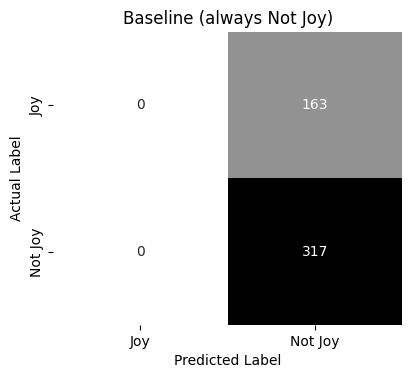

In [32]:
base_name = "Baseline (always Not Joy)"
base = results_df[results_df['Model'] == base_name].iloc[0]

print(f"Baseline Accuracy       = {base['Accuracy']:.2%}")
print(f"Baseline Recall (Joy)   = {base['Recall (Joy)']:.2%}")
print(f"Baseline F1-Score (Joy) = {base['F1-Score (Joy)']:.2%}")

cm = confusion_matrix(y_test, predictions[base_name], labels=['Joy', 'Not Joy'])
plt.figure(figsize=(4.5, 3.8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greys', cbar=False,
            xticklabels=['Joy', 'Not Joy'], yticklabels=['Joy', 'Not Joy'])
plt.title("Baseline (always Not Joy)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

##### **Lesson:** The baseline has about **66% accuracy** but it **never** finds a single Joy comment (Recall = 0). On imbalanced data, a high accuracy alone does **not** mean the model is good. Always check the minority class with Precision, Recall, F1-Score and the confusion matrix.

#### Step 7.4: Confusion Matrices – Variation 1 (without Class Weights)

##### Rows = actual label, columns = predicted label. Look at the first row: how many **Joy** comments were wrongly predicted as **Not Joy**?

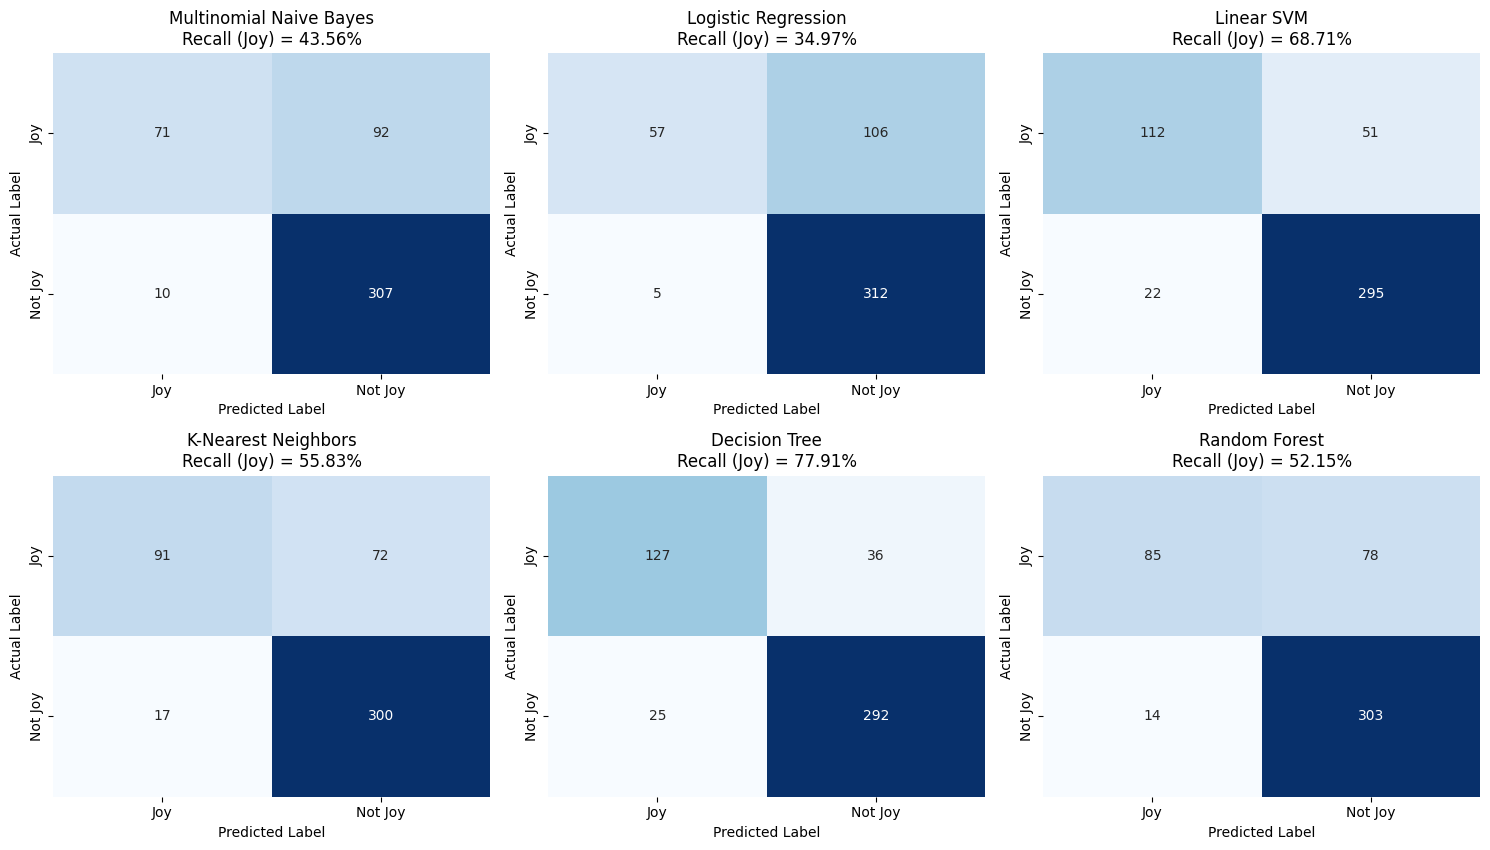

In [33]:
labels = ['Joy', 'Not Joy']

def plot_confusion_matrices(model_names, n_cols, cmap):
    n_rows = (len(model_names) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4.3 * n_rows))
    for ax, name in zip(axes.ravel(), model_names):
        cm = confusion_matrix(y_test, predictions[name], labels=labels)
        sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, cbar=False,
                    xticklabels=labels, yticklabels=labels, ax=ax)
        recall_joy = recall_score(y_test, predictions[name], pos_label='Joy')
        ax.set_title(f"{name}\nRecall (Joy) = {recall_joy:.2%}")
        ax.set_xlabel("Predicted Label")
        ax.set_ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

plot_confusion_matrices(list(variation_1), n_cols=3, cmap='Blues')

#### Step 7.5: Confusion Matrices – Variation 2 (with class_weight = 'balanced')

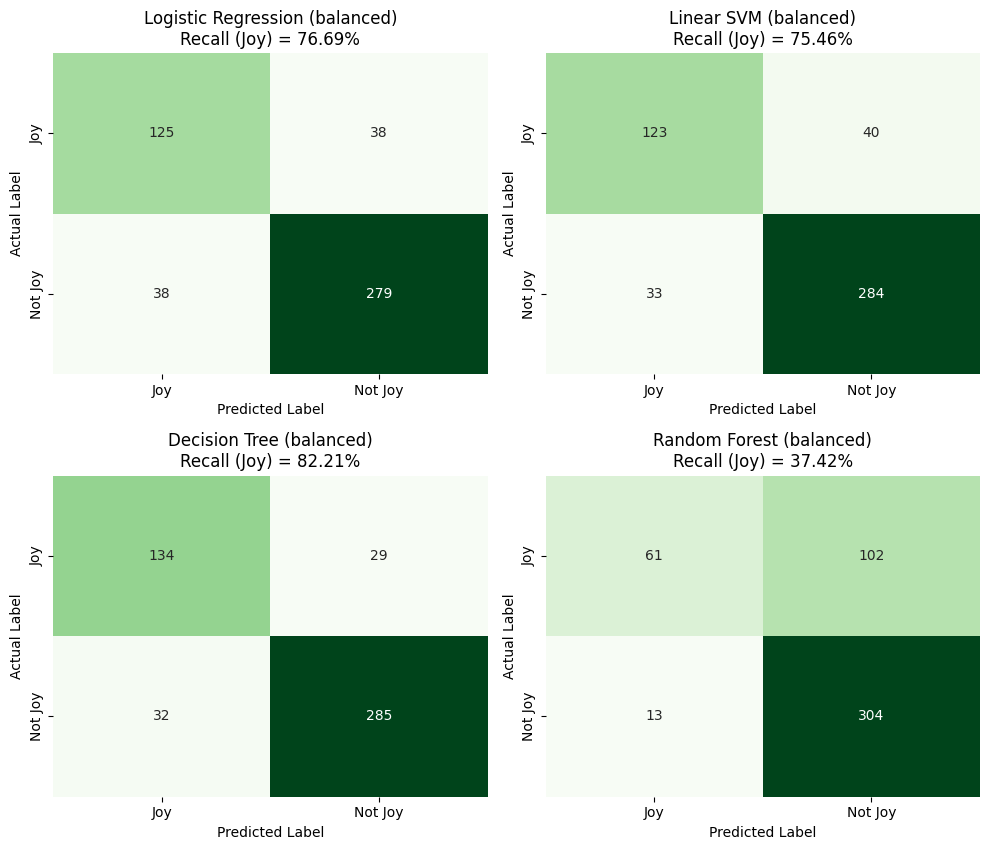

In [34]:
plot_confusion_matrices(list(variation_2), n_cols=2, cmap='Greens')

### Step 8: Compare the Algorithms

#### Step 8.1: Comparison Table of All Models (sorted by F1-Score of Joy)

In [35]:
comparison = results_df.sort_values('F1-Score (Joy)', ascending=False).reset_index(drop=True)
comparison.index = comparison.index + 1          # rank starts from 1
comparison.index.name = 'Rank'

print("\nComparison of All Models:")
print("=========================\n")
comparison.round(4)


Comparison of All Models:



,Model,Variation,Accuracy,Precision (Joy),Recall (Joy),F1-Score (Joy),Macro F1
Rank,,,,,,,
1,Decision Tree (balanced),Variation 2 (balanced),0.8729,0.8072,0.8221,0.8146,0.8590
2,Decision Tree,Variation 1 (no weights),0.8729,0.8355,0.7791,0.8063,0.8559
3,Linear SVM (balanced),Variation 2 (balanced),0.8479,0.7885,0.7546,0.7712,0.8286
4,Logistic Regression (balanced),Variation 2 (balanced),0.8417,0.7669,0.7669,0.7669,0.8235
5,Linear SVM,Variation 1 (no weights),0.8479,0.8358,0.6871,0.7542,0.8221
6,K-Nearest Neighbors,Variation 1 (no weights),0.8146,0.8426,0.5583,0.6716,0.7712
7,Random Forest,Variation 1 (no weights),0.8083,0.8586,0.5215,0.6489,0.7585
8,Multinomial Naive Bayes,Variation 1 (no weights),0.7875,0.8765,0.4356,0.5820,0.7198
9,Random Forest (balanced),Variation 2 (balanced),0.7604,0.8243,0.3742,0.5148,0.6779


#### Step 8.2: Variation 1 vs Variation 2 (Effect of class_weight = 'balanced')

In [36]:
rows = []
for name in variation_2:
    plain = name.replace(" (balanced)", "")
    r1 = results_df[results_df['Model'] == plain].iloc[0]
    r2 = results_df[results_df['Model'] == name].iloc[0]
    rows.append({
        'Algorithm':                plain,
        'Accuracy (no weights)':    r1['Accuracy'],
        'Accuracy (balanced)':      r2['Accuracy'],
        'Recall Joy (no weights)':  r1['Recall (Joy)'],
        'Recall Joy (balanced)':    r2['Recall (Joy)'],
        'F1 Joy (no weights)':      r1['F1-Score (Joy)'],
        'F1 Joy (balanced)':        r2['F1-Score (Joy)'],
    })

before_after = pd.DataFrame(rows).set_index('Algorithm')
before_after['Change in Recall (Joy)'] = before_after['Recall Joy (balanced)'] - before_after['Recall Joy (no weights)']
before_after.round(4)

,Accuracy (no weights),Accuracy (balanced),Recall Joy (no weights),Recall Joy (balanced),F1 Joy (no weights),F1 Joy (balanced),Change in Recall (Joy)
Algorithm,,,,,,,
Logistic Regression,0.7688,0.8417,0.3497,0.7669,0.5067,0.7669,0.4172
Linear SVM,0.8479,0.8479,0.6871,0.7546,0.7542,0.7712,0.0675
Decision Tree,0.8729,0.8729,0.7791,0.8221,0.8063,0.8146,0.0429
Random Forest,0.8083,0.7604,0.5215,0.3742,0.6489,0.5148,-0.1472


##### **Observations:**
- **Logistic Regression** gains the most: without weights it finds only about 1 of every 3 Joy comments; with `class_weight='balanced'` it finds about 3 of every 4.
- **Linear SVM** and **Decision Tree** also find more Joy comments with balanced weights.
- **Random Forest is an exception:** its Recall of Joy goes **down** with balanced weights. Class weights do **not** always help – this is why we always train and compare **both variations** instead of assuming.

#### Step 8.3: Comparison Bar Chart (Recall and F1-Score of Joy)

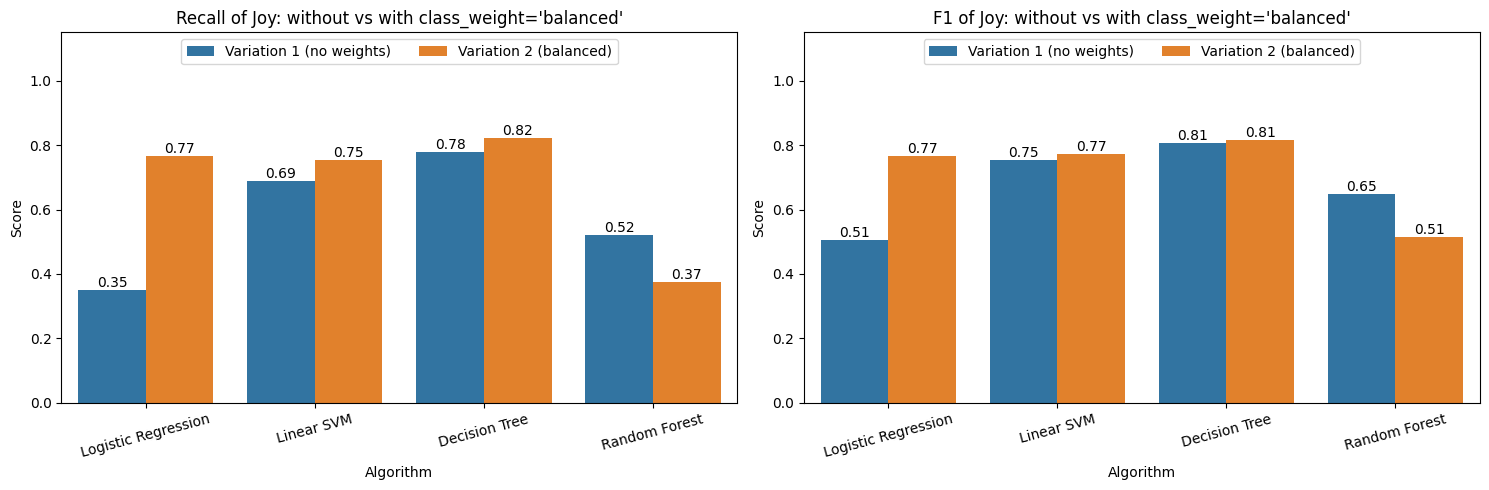

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric in zip(axes, ['Recall', 'F1']):
    chart_df = pd.DataFrame({
        'Algorithm':  before_after.index.tolist() * 2,
        'Variation':  ['Variation 1 (no weights)'] * len(before_after) + ['Variation 2 (balanced)'] * len(before_after),
        'Score':      before_after[f'{metric} Joy (no weights)'].tolist() + before_after[f'{metric} Joy (balanced)'].tolist(),
    })
    sns.barplot(data=chart_df, x='Algorithm', y='Score', hue='Variation', ax=ax)
    ax.set_title(f"{metric} of Joy: without vs with class_weight='balanced'")
    ax.set_ylim(0, 1.15)
    ax.tick_params(axis='x', rotation=15)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f')
    ax.legend(loc='upper center', ncol=2)
plt.tight_layout()
plt.show()

#### Step 8.4: Select and Save the Best Model

In [38]:
# The best model is the one with the highest F1-Score of Joy (first row of the comparison table)
best_name = comparison.loc[1, 'Model']
best_model = loaded_models[best_name]

joblib.dump(best_model, 'best_model.pkl')
print(f"Best model      = {best_name}")
print(f"F1-Score (Joy)  = {comparison.loc[1, 'F1-Score (Joy)']:.4f}")
print(f"Recall (Joy)    = {comparison.loc[1, 'Recall (Joy)']:.4f}")
print("Best model saved as 'best_model.pkl'")

Best model      = Decision Tree (balanced)
F1-Score (Joy)  = 0.8146
Recall (Joy)    = 0.8221
Best model saved as 'best_model.pkl'


#### Step 8.5: Detailed Classification Report of the Best Model

In [39]:
print(f"Classification Report - {best_name}:")
print("===================================================\n")
print(classification_report(y_test, predictions[best_name], digits=4))

Classification Report - Decision Tree (balanced):

              precision    recall  f1-score   support

         Joy     0.8072    0.8221    0.8146       163
     Not Joy     0.9076    0.8991    0.9033       317

    accuracy                         0.8729       480
   macro avg     0.8574    0.8606    0.8590       480
weighted avg     0.8735    0.8729    0.8732       480



### Step 9: Execute the Application Phase

#### Step 9.1: Load tfidf_vectorizer (saved in Step 5.4)

In [40]:
loaded_vectorizer = joblib.load('tfidf_vectorizer.pkl')
print("tfidf_vectorizer loaded from 'tfidf_vectorizer.pkl'")

tfidf_vectorizer loaded from 'tfidf_vectorizer.pkl'


#### Step 9.2: Load the Best Model (saved in Step 8.4)

In [41]:
loaded_best_model = joblib.load('best_model.pkl')
print("Best model loaded from 'best_model.pkl':", type(loaded_best_model).__name__)

Best model loaded from 'best_model.pkl': DecisionTreeClassifier


#### Step 9.3: Take Input from User

##### Write your own comment in the variable below (or replace it with `user_comment = input("Enter a comment: ")`).

In [42]:
user_comment = "I feel so happy and excited about the weekend trip with my friends"
print("User Input:", user_comment)

User Input: I feel so happy and excited about the weekend trip with my friends


#### Step 9.4: Clean and Preprocess User Input (exactly as you did for Sample Data in Step 3)

In [43]:
clean_user_comment = clean_text(user_comment)
print("Cleaned User Input:", clean_user_comment)

Cleaned User Input: feel happy excited weekend trip friends


#### Step 9.5: Apply tfidf_vectorizer to Cleaned and Preprocessed User Input (transform User Input into Feature Vector)

In [44]:
user_feature_vector = loaded_vectorizer.transform([clean_user_comment])
print("Shape of the feature vector =", user_feature_vector.shape)

Shape of the feature vector = (1, 2000)


#### Step 9.6: Model Prediction

##### Step 9.6.1: Apply the Best Model to the Feature Vector of the Unseen Instance (created in Step 9.5) and Return Prediction to the User

In [45]:
predicted_label = loaded_best_model.predict(user_feature_vector)[0]
print("User Input      :", user_comment)
print("Predicted Label :", predicted_label)

User Input      : I feel so happy and excited about the weekend trip with my friends
Predicted Label : Joy


##### Step 9.6.2: Predict More Unseen Comments

In [46]:
unseen_comments = [
    "I am feeling really excited about my results today",
    "I feel so lonely since my best friend moved away",
    "I feel furious that they cancelled my order without asking",
    "I feel nervous and scared about tomorrow's exam",
    "I feel so lucky and loved to have such a caring family",
    "I feel cheerful and content after a peaceful morning walk",
]

unseen_vectors = loaded_vectorizer.transform([clean_text(c) for c in unseen_comments])
unseen_predictions = loaded_best_model.predict(unseen_vectors)

pd.DataFrame({'Comment': unseen_comments, 'Predicted Label': unseen_predictions})

,Comment,Predicted Label
0,I am feeling really excited about my results t...,Joy
1,I feel so lonely since my best friend moved away,Not Joy
2,I feel furious that they cancelled my order wi...,Not Joy
3,I feel nervous and scared about tomorrow's exam,Not Joy
4,I feel so lucky and loved to have such a carin...,Not Joy
5,I feel cheerful and content after a peaceful m...,Joy


##### **Note:** The model is not always right. Check which of the predictions above are wrong – such mistakes are exactly the feedback collected in Step 10.

### Step 10: Execute the Feedback Phase
#### Step 10.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World
#### Step 10.2: Make a List of Potential Improvements
- Use more training data (the full dataset has 16,000 training comments).
- Try other ways of handling imbalanced data, e.g. **over-sampling** the minority class or **under-sampling** the majority class.
- Change the **decision threshold** of models that give probabilities (e.g., Logistic Regression) to find more Joy comments.
- Try different values of max_features, or word pairs with `ngram_range=(1, 2)`.
- Use Stratified K-Fold Cross Validation for a more reliable comparison.
#### Step 10.3: Improve the Model Based on Feedback

## Lessons Learned about Imbalanced Data
| **Sr. No** | **Lesson** |
| ---------- | ---------- |
| 1 | Always **count the classes** first (Step 2.4). Imbalanced data needs special care. |
| 2 | **Accuracy can be misleading:** the baseline that always predicts *Not Joy* gets about 66% accuracy but finds **no** Joy comment (Step 7.3). |
| 3 | Use **stratify** when splitting, so training and testing sets keep the same class percentages (Step 4.1). |
| 4 | Judge models by **Precision, Recall and F1-Score of the minority class** and the **confusion matrix**, not by accuracy alone (Step 7). |
| 5 | **`class_weight='balanced'`** makes mistakes on the minority class more costly. It usually **increases Recall of Joy** (more Joy comments found), sometimes at the cost of a little Precision. But it does **not always** help (Random Forest got worse), so always compare both variations (Step 8.2). |
| 6 | Not every algorithm supports `class_weight` (e.g., Multinomial Naive Bayes, K-Nearest Neighbors). |

## Conclusion
##### This notebook is a complete machine learning pipeline for **joy detection from English comments** – a **binary classification** problem with **imbalanced data** (about 1 Joy comment for every 2 Not Joy comments). A random sample of 2,400 comments was cleaned, split 80% / 20% (stratified), converted into TF-IDF feature vectors (2000 words), and used to train a **baseline** and **six algorithms in two variations** (without and with `class_weight='balanced'`). The comparison shows why accuracy alone is not enough for imbalanced data and how class weights help the models find more comments of the minority class. The best model (highest F1-Score of Joy) was saved and used to predict new, unseen comments.